In [2]:
%pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 10.0 MB/s  0:00:019.0 MB/s eta 0:00:01

[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import time
from urllib.parse import quote

In [6]:
compounds = ["glucose", "fructose", "sucrose", "citric acid", "ascorbic acid", "lactic acid", "glycerol", "urea", "glycine", "alanine"]

print(f"Number of compounds selected: {len(compounds)}")

Number of compounds selected: 10


In [7]:
url = ("https://pubchem.ncbi.nlm.nih.gov/rest/pug/" "compound/name/glucose/property/" "MolecularFormula,MolecularWeight,HBondDonorCount," "HBondAcceptorCount/JSON")

response = requests.get(url, timeout=30)
response.raise_for_status()

data = response.json()

print(data["PropertyTable"]["Properties"][0])

{'CID': 5793, 'MolecularFormula': 'C6H12O6', 'MolecularWeight': '180.16', 'HBondDonorCount': 5, 'HBondAcceptorCount': 6}


In [8]:
properties = ("MolecularFormula," "MolecularWeight," "HBondDonorCount," "HBondAcceptorCount")

records = []

for compound in compounds:
    url = ("https://pubchem.ncbi.nlm.nih.gov/rest/pug/" f"compound/name/{quote(compound)}/" f"property/{properties}/JSON")

    try:
        response = requests.get(url, timeout=30)
        response.raise_for_status()

        result = response.json()
        item = result["PropertyTable"]["Properties"][0]

        records.append({"Compound": compound.title(), "CID": item["CID"], "Formula": item.get("MolecularFormula"), "Molecular Weight (g/mol)": item.get("MolecularWeight"), "H-Bond Donors": item.get("HBondDonorCount"), "H-Bond Acceptors": item.get("HBondAcceptorCount")})

        print(f"Retrieved: {compound}")

    except (requests.RequestException, KeyError, IndexError, ValueError) as error:
        print(f"Could not retrieve {compound}: {error}")

    time.sleep(0.25)

df = pd.DataFrame(records)

df

Retrieved: glucose
Retrieved: fructose
Retrieved: sucrose
Retrieved: citric acid
Retrieved: ascorbic acid
Retrieved: lactic acid
Retrieved: glycerol
Retrieved: urea
Retrieved: glycine
Retrieved: alanine


,Compound,CID,Formula,Molecular Weight (g/mol),H-Bond Donors,H-Bond Acceptors
0,Glucose,5793,C6H12O6,180.16,5,6
1,Fructose,2723872,C6H12O6,180.16,5,6
2,Sucrose,5988,C12H22O11,342.30,8,11
3,Citric Acid,311,C6H8O7,192.12,4,7
4,Ascorbic Acid,54670067,C6H8O6,176.12,4,6
5,Lactic Acid,612,C3H6O3,90.08,2,3
6,Glycerol,753,C3H8O3,92.09,3,3
7,Urea,1176,CH4N2O,60.056,2,1
8,Glycine,750,C2H5NO2,75.07,2,3
9,Alanine,5950,C3H7NO2,89.09,2,3


In [9]:
print("Successful records:", len(df))
print("Missing values by column:")
print(df.isna().sum())

df = df.dropna(subset=["Molecular Weight (g/mol)", "H-Bond Donors", "H-Bond Acceptors"]).copy()

df = df.sort_values("Molecular Weight (g/mol)", ascending=False).reset_index(drop=True)

df.round(2)

Successful records: 10
Missing values by column:
Compound                    0
CID                         0
Formula                     0
Molecular Weight (g/mol)    0
H-Bond Donors               0
H-Bond Acceptors            0
dtype: int64


,Compound,CID,Formula,Molecular Weight (g/mol),H-Bond Donors,H-Bond Acceptors
0,Glycerol,753,C3H8O3,92.09,3,3
1,Lactic Acid,612,C3H6O3,90.08,2,3
2,Alanine,5950,C3H7NO2,89.09,2,3
3,Glycine,750,C2H5NO2,75.07,2,3
4,Urea,1176,CH4N2O,60.056,2,1
5,Sucrose,5988,C12H22O11,342.30,8,11
6,Citric Acid,311,C6H8O7,192.12,4,7
7,Glucose,5793,C6H12O6,180.16,5,6
8,Fructose,2723872,C6H12O6,180.16,5,6
9,Ascorbic Acid,54670067,C6H8O6,176.12,4,6


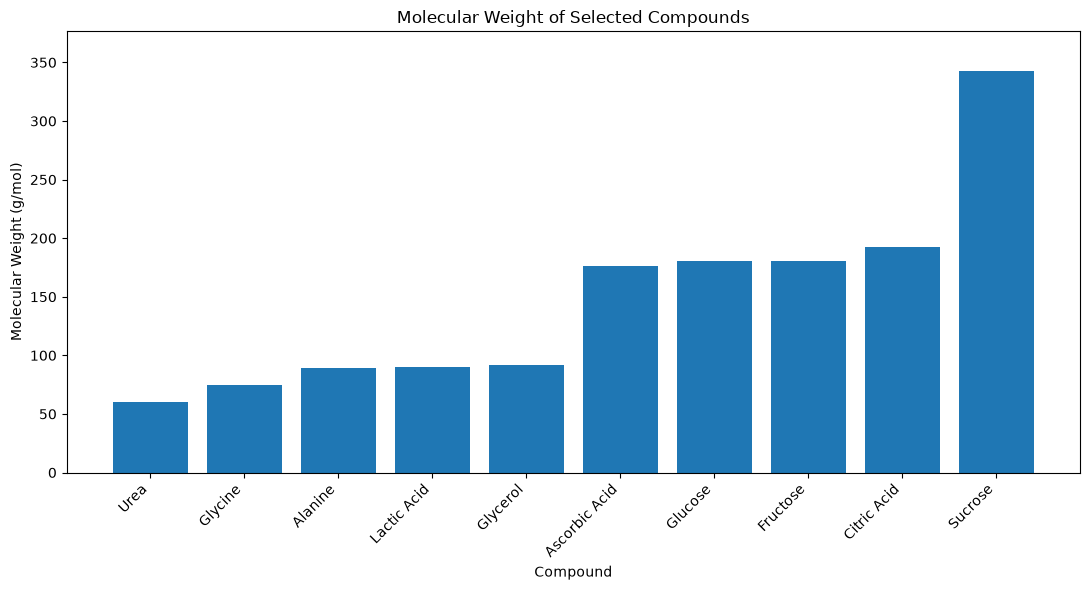

In [13]:
df["Molecular Weight (g/mol)"] = pd.to_numeric(df["Molecular Weight (g/mol)"], errors="coerce")

df_sorted = df.sort_values(by="Molecular Weight (g/mol)", ascending=True).copy()

plt.figure(figsize=(11, 6))

plt.bar(df_sorted["Compound"], df_sorted["Molecular Weight (g/mol)"])

plt.title("Molecular Weight of Selected Compounds")
plt.xlabel("Compound")
plt.ylabel("Molecular Weight (g/mol)")
plt.xticks(rotation=45, ha="right")

plt.ylim(0, df_sorted["Molecular Weight (g/mol)"].max() * 1.1)

plt.tight_layout()
plt.show()

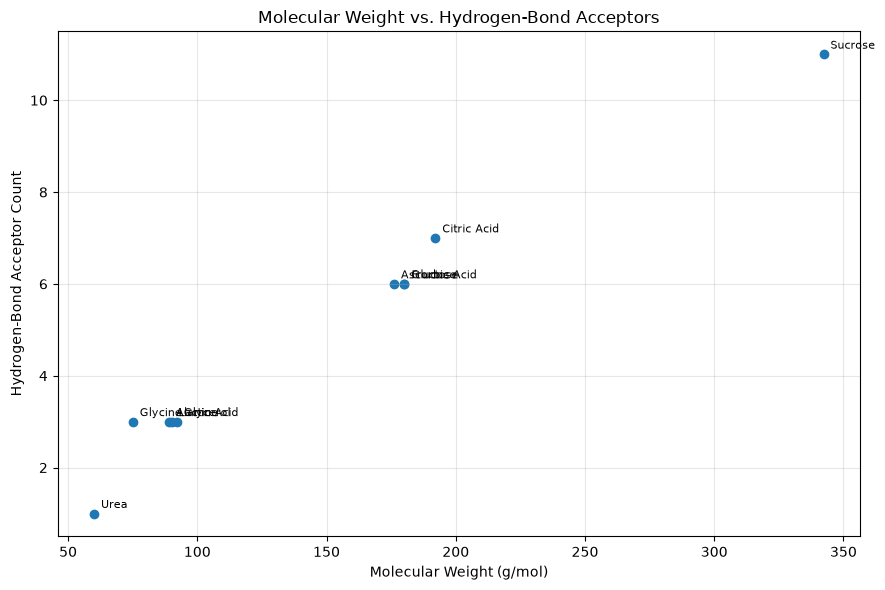

In [14]:
plt.figure(figsize=(9, 6))

plt.scatter(df["Molecular Weight (g/mol)"], df["H-Bond Acceptors"])

for _, row in df.iterrows(): plt.annotate(row["Compound"], (row["Molecular Weight (g/mol)"], row["H-Bond Acceptors"]), xytext=(5, 4), textcoords="offset points", fontsize=8)

plt.title("Molecular Weight vs. Hydrogen-Bond Acceptors")
plt.xlabel("Molecular Weight (g/mol)")
plt.ylabel("Hydrogen-Bond Acceptor Count")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
correlation = df[["Molecular Weight (g/mol)", "H-Bond Acceptors"]].corr().iloc[0, 1]

print("Correlation between molecular weight and " f"hydrogen-bond acceptor count: {correlation:.3f}")

Correlation between molecular weight and hydrogen-bond acceptor count: 0.988


In this project, an API from PubChem was used to retrieve molecular properties for ten common organic compounds that are typically found in the human body. Data was organized and retrieved using pandas. Molecular weight and hydrogen-bond acceptor counts were obtained using matplotlib. The graphs allowed comparison of the compounds and explored the relationship between molecular size and hydrogen-bonding properties. As you can see above, the larger the molecule, the more H-bond acceptors present in the molecule. This makes sense as oxygen and nitrogen are typical H-bond acceptors, and are larger elements than carbon or hydrogen.